# TREC Question Classification — Classical Machine Learning

## Research question
**How does increasing the granularity of question categories affect the performance of classical NLP classifiers?**

We compare:
- **Complement Naive Bayes**
- **Linear SVM**

Representation:
- **TF-IDF word unigrams + bigrams**

Tasks:
1. **Coarse:** 6 question categories
2. **Fine:** 50 question categories

The validation set is used for **model/hyperparameter selection**. The test set is kept untouched until final evaluation.

> **SMOTE is not used** because TF-IDF text is high-dimensional and sparse. Linear SVM uses class weighting.


## 1. Load and inspect the data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from itertools import product
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, ConfusionMatrixDisplay
)

train = pd.read_parquet("train.parquet")
validation = pd.read_parquet("validation.parquet")
test = pd.read_parquet("test.parquet")

print("Train:", train.shape)
print("Validation:", validation.shape)
print("Test:", test.shape)

display(train.head())


Train: (4907, 5)
Validation: (545, 5)
Test: (500, 5)


,text,coarse_label,coarse_description,fine_label,fine_description
0,What writer is famous for physically putting h...,HUM,human beings,HUM:ind,an individual
1,How many calories are in a tomato ?,NUM,numeric values,NUM:count,counts
2,What kind of creature is a coot ?,ENTY,entities,ENTY:animal,animals
3,Who is Samuel F. Pickering ?,HUM,human beings,HUM:desc,description of a person
4,"What `` melts in your mouth , not in your hand...",ENTY,entities,ENTY:food,food


In [6]:
print("Coarse class distribution:")
display(train["coarse_label"].value_counts().sort_index())

fine_counts = train["fine_label"].value_counts().sort_index()
print("\nNumber of fine classes:", fine_counts.size)
display(fine_counts)


Coarse class distribution:


,count
coarse_label,
ABBR,74
DESC,1029
ENTY,1108
HUM,1115
LOC,759
NUM,822



Number of fine classes: 50


,count
fine_label,
ABBR:abb,15
ABBR:exp,59
DESC:def,379
DESC:desc,234
DESC:manner,246
DESC:reason,170
ENTY:animal,101
ENTY:body,14
ENTY:color,34


## 2. Evaluation helpers

For the 6-class task, all test classes have adequate support.

For the 50-class task, some fine classes have **zero test observations**. Standard macro F1 treats those absent classes as 0, which can make the metric partly reflect test-set coverage rather than model quality.

Therefore, for the fine task we report:
- **Macro F1 (all 50 labels)** — conventional but affected by zero-support labels
- **Macro F1 (supported labels)** — averages only over labels actually present in the evaluation split
- Weighted F1
- Accuracy

The supported-label macro F1 is used for model selection.


In [7]:
def evaluate(y_true, y_pred, labels=None):
    y_true = pd.Series(y_true)
    y_pred = pd.Series(y_pred)

    if labels is None:
        labels = sorted(y_true.unique())

    supported = [lab for lab in labels if (y_true == lab).sum() > 0]

    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "Macro F1 (supported)": f1_score(
            y_true, y_pred, labels=supported, average="macro", zero_division=0
        ),
        "Weighted F1": f1_score(
            y_true, y_pred, labels=labels, average="weighted", zero_division=0
        ),
        "Supported classes": len(supported),
        "Total classes": len(labels)
    }

def tune_model(task, model_name, Xtr, ytr, Xval, yval, labels):
    # Small, deliberate grids: enough to make a fair comparison,
    # without turning this into an exhaustive hyperparameter search.
    if model_name == "Complement NB":
        configs = [{"alpha": a} for a in [0.1, 0.5, 1.0, 2.0]]
    else:
        configs = [{"C": c} for c in [0.25, 0.5, 1.0, 2.0]]

    rows = []

    for cfg in configs:
        if model_name == "Complement NB":
            model = ComplementNB(alpha=cfg["alpha"])
        else:
            model = LinearSVC(
                C=cfg["C"],
                class_weight="balanced",
                random_state=42
            )

        model.fit(Xtr, ytr)
        pred = model.predict(Xval)
        result = evaluate(yval, pred, labels=labels)
        rows.append({"Model": model_name, **cfg, **result})

    tuning = pd.DataFrame(rows).sort_values(
        "Macro F1 (supported)", ascending=False
    ).reset_index(drop=True)

    best_cfg = tuning.iloc[0].to_dict()
    return tuning, best_cfg


## 3. Coarse task — TF-IDF tuning and model selection

In [8]:
coarse_labels = sorted(train["coarse_label"].unique())

# A small TF-IDF grid is selected using validation Macro F1.
tfidf_configs = [
    {"ngram_range": (1, 1), "min_df": 1},
    {"ngram_range": (1, 2), "min_df": 1},
    {"ngram_range": (1, 2), "min_df": 2},
    {"ngram_range": (1, 2), "min_df": 3},
]

coarse_tuning_rows = []

for cfg in tfidf_configs:
    vec = TfidfVectorizer(
        lowercase=True,
        ngram_range=cfg["ngram_range"],
        min_df=cfg["min_df"],
        max_df=0.95,
        sublinear_tf=True
    )

    Xtr = vec.fit_transform(train["text"])
    Xval = vec.transform(validation["text"])

    for model_name in ["Complement NB", "Linear SVM"]:
        tuning, best = tune_model(
            "coarse", model_name,
            Xtr, train["coarse_label"],
            Xval, validation["coarse_label"],
            coarse_labels
        )

        best_row = tuning.iloc[0].to_dict()
        best_row.update({
            "ngram_range": str(cfg["ngram_range"]),
            "min_df": cfg["min_df"]
        })
        coarse_tuning_rows.append(best_row)

coarse_tuning = pd.DataFrame(coarse_tuning_rows).sort_values(
    "Macro F1 (supported)", ascending=False
).reset_index(drop=True)

display(coarse_tuning)


,Model,alpha,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro F1 (supported),Weighted F1,Supported classes,Total classes,ngram_range,min_df,C
0,Linear SVM,NaN,0.853211,0.879418,0.870504,0.874398,0.874398,0.853396,6,6,"(1, 2)",2,0.50
1,Linear SVM,NaN,0.842202,0.873642,0.838302,0.852744,0.852744,0.842370,6,6,"(1, 2)",3,0.25
2,Linear SVM,NaN,0.827523,0.856810,0.840151,0.846326,0.846326,0.827458,6,6,"(1, 1)",1,0.25
3,Linear SVM,NaN,0.842202,0.874566,0.827823,0.845281,0.845281,0.841638,6,6,"(1, 2)",1,2.00
4,Complement NB,1.0,0.801835,0.830017,0.832460,0.822910,0.822910,0.796115,6,6,"(1, 2)",1,NaN
5,Complement NB,1.0,0.801835,0.830201,0.829721,0.821885,0.821885,0.794918,6,6,"(1, 2)",2,NaN
6,Complement NB,1.0,0.790826,0.823112,0.796239,0.795760,0.795760,0.783003,6,6,"(1, 2)",3,NaN
7,Complement NB,2.0,0.746789,0.785794,0.775434,0.767715,0.767715,0.741428,6,6,"(1, 1)",1,NaN


## 4. Fine task — TF-IDF tuning and model selection

In [9]:
fine_labels = sorted(train["fine_label"].unique())

fine_tuning_rows = []

for cfg in tfidf_configs:
    vec = TfidfVectorizer(
        lowercase=True,
        ngram_range=cfg["ngram_range"],
        min_df=cfg["min_df"],
        max_df=0.95,
        sublinear_tf=True
    )

    Xtr = vec.fit_transform(train["text"])
    Xval = vec.transform(validation["text"])

    for model_name in ["Complement NB", "Linear SVM"]:
        tuning, best = tune_model(
            "fine", model_name,
            Xtr, train["fine_label"],
            Xval, validation["fine_label"],
            fine_labels
        )

        best_row = tuning.iloc[0].to_dict()
        best_row.update({
            "ngram_range": str(cfg["ngram_range"]),
            "min_df": cfg["min_df"]
        })
        fine_tuning_rows.append(best_row)

fine_tuning = pd.DataFrame(fine_tuning_rows).sort_values(
    "Macro F1 (supported)", ascending=False
).reset_index(drop=True)

display(fine_tuning)


,Model,alpha,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro F1 (supported),Weighted F1,Supported classes,Total classes,ngram_range,min_df,C
0,Linear SVM,NaN,0.792661,0.612300,0.629698,0.606353,0.689038,0.784363,44,50,"(1, 2)",1,2.0
1,Linear SVM,NaN,0.765138,0.575123,0.611481,0.579256,0.658246,0.761129,44,50,"(1, 1)",1,2.0
2,Linear SVM,NaN,0.763303,0.556210,0.622852,0.569113,0.646719,0.766556,44,50,"(1, 2)",2,0.5
3,Linear SVM,NaN,0.757798,0.537088,0.583582,0.544521,0.618774,0.757019,44,50,"(1, 2)",3,2.0
4,Complement NB,0.5,0.706422,0.549042,0.527202,0.515246,0.585506,0.683015,44,50,"(1, 2)",1,NaN
5,Complement NB,2.0,0.706422,0.561699,0.501908,0.503274,0.571903,0.673524,44,50,"(1, 2)",2,NaN
6,Complement NB,2.0,0.711927,0.548291,0.504835,0.499968,0.568146,0.678883,44,50,"(1, 2)",3,NaN
7,Complement NB,2.0,0.653211,0.547894,0.463640,0.472624,0.537073,0.628606,44,50,"(1, 1)",1,NaN


## 5. Final evaluation

After validation-based selection, each winning configuration is **refit on train + validation**.

The test set is used **only here** for the final unbiased evaluation.


In [10]:
def fit_final_and_test(tuning_df, labels, target_col):
    best = tuning_df.iloc[0]

    ngram = eval(best["ngram_range"])
    min_df = int(best["min_df"])

    vec = TfidfVectorizer(
        lowercase=True,
        ngram_range=ngram,
        min_df=min_df,
        max_df=0.95,
        sublinear_tf=True
    )

    combined_text = pd.concat(
        [train["text"], validation["text"]], ignore_index=True
    )
    combined_y = pd.concat(
        [train[target_col], validation[target_col]], ignore_index=True
    )

    X_combined = vec.fit_transform(combined_text)
    X_test = vec.transform(test["text"])

    if best["Model"] == "Complement NB":
        model = ComplementNB(alpha=float(best["alpha"]))
    else:
        model = LinearSVC(
            C=float(best["C"]),
            class_weight="balanced",
            random_state=42
        )

    model.fit(X_combined, combined_y)
    pred = model.predict(X_test)

    return best, model, vec, pred

best_coarse, coarse_model, coarse_vectorizer, coarse_pred = fit_final_and_test(
    coarse_tuning, coarse_labels, "coarse_label"
)

best_fine, fine_model, fine_vectorizer, fine_pred = fit_final_and_test(
    fine_tuning, fine_labels, "fine_label"
)

coarse_test_metrics = evaluate(
    test["coarse_label"], coarse_pred, coarse_labels
)

fine_test_metrics = evaluate(
    test["fine_label"], fine_pred, fine_labels
)

final_results = pd.DataFrame([
    {"Task": "Coarse (6 classes)", "Model": best_coarse["Model"], **coarse_test_metrics},
    {"Task": "Fine (50 classes)", "Model": best_fine["Model"], **fine_test_metrics}
])

display(final_results)


,Task,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Macro F1 (supported),Weighted F1,Supported classes,Total classes
0,Coarse (6 classes),Linear SVM,0.894,0.894239,0.873799,0.882187,0.882187,0.893657,6,6
1,Fine (50 classes),Linear SVM,0.824,0.645233,0.631258,0.616589,0.734034,0.810550,42,50


## 6. Detailed coarse-task report

In [11]:
print("Selected coarse model:", best_coarse["Model"])
print("Selected TF-IDF:", best_coarse["ngram_range"], "min_df =", int(best_coarse["min_df"]))

if best_coarse["Model"] == "Linear SVM":
    print("Selected C:", best_coarse["C"])
else:
    print("Selected alpha:", best_coarse["alpha"])

print("\nFinal test classification report:")
print(classification_report(
    test["coarse_label"],
    coarse_pred,
    labels=coarse_labels,
    digits=4,
    zero_division=0
))


Selected coarse model: Linear SVM
Selected TF-IDF: (1, 2) min_df = 2
Selected C: 0.5

Final test classification report:
              precision    recall  f1-score   support

        ABBR     0.8750    0.7778    0.8235         9
        DESC     0.8581    0.9638    0.9078       138
        ENTY     0.8391    0.7766    0.8066        94
         HUM     0.9242    0.9385    0.9313        65
         LOC     0.8690    0.9012    0.8848        81
         NUM     1.0000    0.8850    0.9390       113

    accuracy                         0.8940       500
   macro avg     0.8942    0.8738    0.8822       500
weighted avg     0.8973    0.8940    0.8937       500



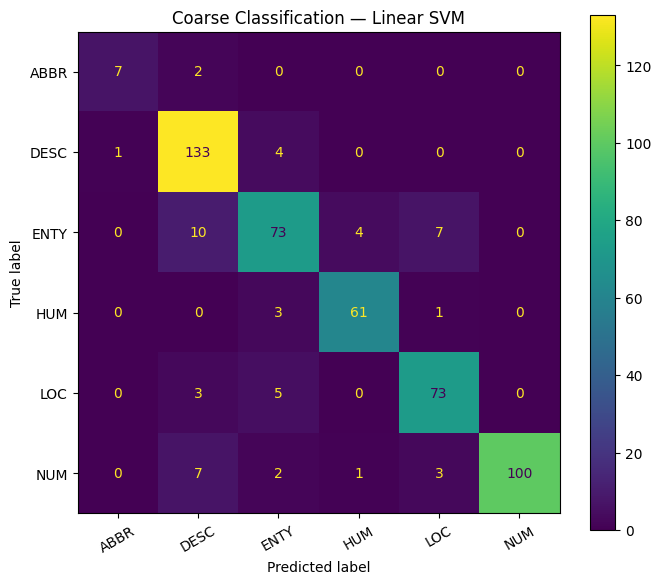

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    test["coarse_label"],
    coarse_pred,
    labels=coarse_labels,
    ax=ax,
    values_format="d"
)
ax.set_title(f"Coarse Classification — {best_coarse['Model']}")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


## 7. Answer the research question

The following cell produces a concise data-based interpretation rather than leaving the notebook at a results table.


In [13]:
coarse_f1 = final_results.loc[
    final_results["Task"] == "Coarse (6 classes)", "Macro F1"
].iloc[0]

fine_f1_supported = final_results.loc[
    final_results["Task"] == "Fine (50 classes)", "Macro F1 (supported)"
].iloc[0]

coarse_weighted = final_results.loc[
    final_results["Task"] == "Coarse (6 classes)", "Weighted F1"
].iloc[0]

fine_weighted = final_results.loc[
    final_results["Task"] == "Fine (50 classes)", "Weighted F1"
].iloc[0]

print("RESEARCH QUESTION ANSWER")
print("=" * 60)
print(
    f"The selected {best_coarse['Model']} achieved a coarse-task "
    f"supported Macro F1 of {coarse_f1:.3f} and Weighted F1 of {coarse_weighted:.3f}."
)
print(
    f"For the fine-grained task, the selected {best_fine['Model']} achieved "
    f"a supported-class Macro F1 of {fine_f1_supported:.3f} "
    f"and Weighted F1 of {fine_weighted:.3f}."
)
print(
    f"Moving from 6 broad classes to 50 fine classes reduced supported-class "
    f"Macro F1 by approximately {coarse_f1 - fine_f1_supported:.3f}."
)


RESEARCH QUESTION ANSWER
The selected Linear SVM achieved a coarse-task supported Macro F1 of 0.882 and Weighted F1 of 0.894.
For the fine-grained task, the selected Linear SVM achieved a supported-class Macro F1 of 0.734 and Weighted F1 of 0.811.
Moving from 6 broad classes to 50 fine classes reduced supported-class Macro F1 by approximately 0.148.


## 8. Final conclusion

### What the project demonstrates

1. **Linear SVM vs Complement Naive Bayes:** the validation set determines which model and hyperparameters are selected.
2. **Granularity effect:** classifying 50 specific question types is harder than classifying 6 broad types.
3. **Imbalance matters:** some fine-grained categories have very limited training data and show poor class-level performance.
4. **Macro vs weighted F1:** Macro F1 gives equal importance to each supported class, while Weighted F1 is influenced by the larger classes.